In [2]:
import numpy, pandas, scipy, matplotlib, sklearn, xgboost
print(numpy.__version__, xgboost.__version__)

2.5.3 3.4.1


In [4]:
def discharge_table(name):
    rows, n = [], 0
    for c in load_cell(name):
        if c['type'] == 'discharge':
            n += 1
            d = c['data']
            rows.append(dict(cell=name, cycle=n, capacity=float(d['Capacity']),
                             V=d['Voltage_measured'], I=d['Current_measured'],
                             Temp=d['Temperature_measured'], t=d['Time']))
    df = pd.DataFrame(rows)
    df['SOH'] = df.capacity / df.capacity.iloc[0] * 100
    return df

df5 = discharge_table('B0005')
print(len(df5), df5.SOH.iloc[[0, -1]].round(1).tolist())

168 [100.0, 71.4]


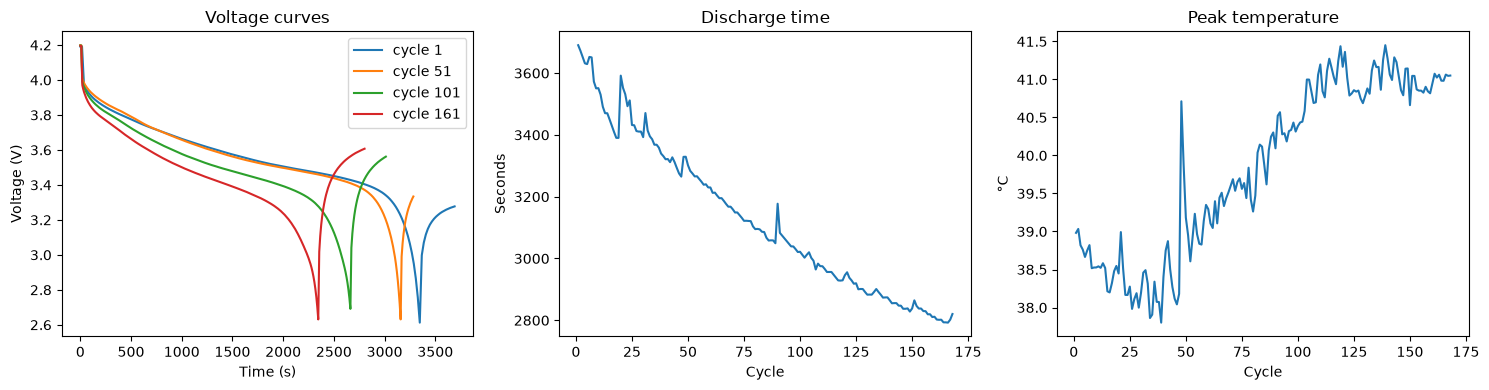

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1. Voltage curves at different ages
for k in [0, 50, 100, 160]:
    ax[0].plot(df5.t[k], df5.V[k], label=f'cycle {k+1}')
ax[0].set_title('Voltage curves'); ax[0].set_xlabel('Time (s)'); ax[0].set_ylabel('Voltage (V)')
ax[0].legend()

# 2. Discharge duration per cycle
ax[1].plot(df5.cycle, [t[-1] for t in df5.t])
ax[1].set_title('Discharge time'); ax[1].set_xlabel('Cycle'); ax[1].set_ylabel('Seconds')

# 3. Peak temperature per cycle
ax[2].plot(df5.cycle, [T.max() for T in df5.Temp])
ax[2].set_title('Peak temperature'); ax[2].set_xlabel('Cycle'); ax[2].set_ylabel('°C')

plt.tight_layout()
plt.show()

In [6]:
# Load all four batteries into one table
cells = ['B0005', 'B0006', 'B0007', 'B0018']
df = pd.concat([discharge_table(n) for n in cells], ignore_index=True)

# One row of health indicators per discharge cycle
def features(r):
    V, I, Temp, t = r.V, r.I, r.Temp, r.t
    below = np.where(V < 3.5)[0]
    i35 = below[0] if len(below) else len(V) - 1
    return pd.Series({
        'dur': t[-1] - t[0],                      # discharge duration (s)
        't_to_3.5V': t[i35],                      # time to reach 3.5 V
        'V_mean': V.mean(),
        'V_min': V.min(),
        'T_max': Temp.max(),
        'T_mean': Temp.mean(),
        'I_mean': np.abs(I).mean(),
        'energy': np.trapezoid(V * np.abs(I), t), # energy discharged
    })

X = df.apply(features, axis=1)
y = df['SOH']
groups = df['cell']

print(X.shape)
print(df.groupby('cell').size())
print(X.assign(SOH=y).corr()['SOH'].round(3))

(636, 8)
cell
B0005    168
B0006    168
B0007    168
B0018    132
dtype: int64
dur          0.889
t_to_3.5V    0.990
V_mean       0.955
V_min       -0.200
T_max       -0.560
T_mean      -0.562
I_mean       0.882
energy       0.967
SOH          1.000
Name: SOH, dtype: float64


In [7]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

def report(yt, yp):
    return dict(RMSE=mean_squared_error(yt, yp) ** 0.5,
                MAE=mean_absolute_error(yt, yp),
                R2=r2_score(yt, yp))

data = X.assign(cycle=df['cycle'])
feat = list(X.columns)

models = {
    'baseline (cycle only)': (LinearRegression(), ['cycle']),
    'ridge': (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), feat),
    'random forest': (RandomForestRegressor(n_estimators=300, random_state=0), feat),
    'xgboost': (XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05), feat),
}

results = []
for name, (m, cols) in models.items():
    for tr, te in LeaveOneGroupOut().split(data, y, groups):
        m.fit(data.iloc[tr][cols], y.iloc[tr])
        p = m.predict(data.iloc[te][cols])
        results.append(dict(model=name, held_out=groups.iloc[te[0]], **report(y.iloc[te], p)))

res = pd.DataFrame(results)
print(res.groupby('model')[['RMSE', 'MAE', 'R2']].mean().round(3))
print()
print(res.pivot(index='model', columns='held_out', values='RMSE').round(2))

                        RMSE    MAE     R2
model                                     
baseline (cycle only)  5.895  5.322  0.603
random forest          3.389  3.043  0.868
ridge                  3.965  3.845  0.817
xgboost                3.349  2.981  0.864

held_out               B0005  B0006  B0007  B0018
model                                            
baseline (cycle only)   3.92   9.23   7.30   3.12
random forest           1.50   7.07   2.15   2.83
ridge                   1.73   6.07   4.26   3.79
xgboost                 1.02   7.21   2.32   2.84


cell
B0005    69.3
B0006    56.7
B0007    74.1
B0018    72.3
Name: SOH, dtype: float64


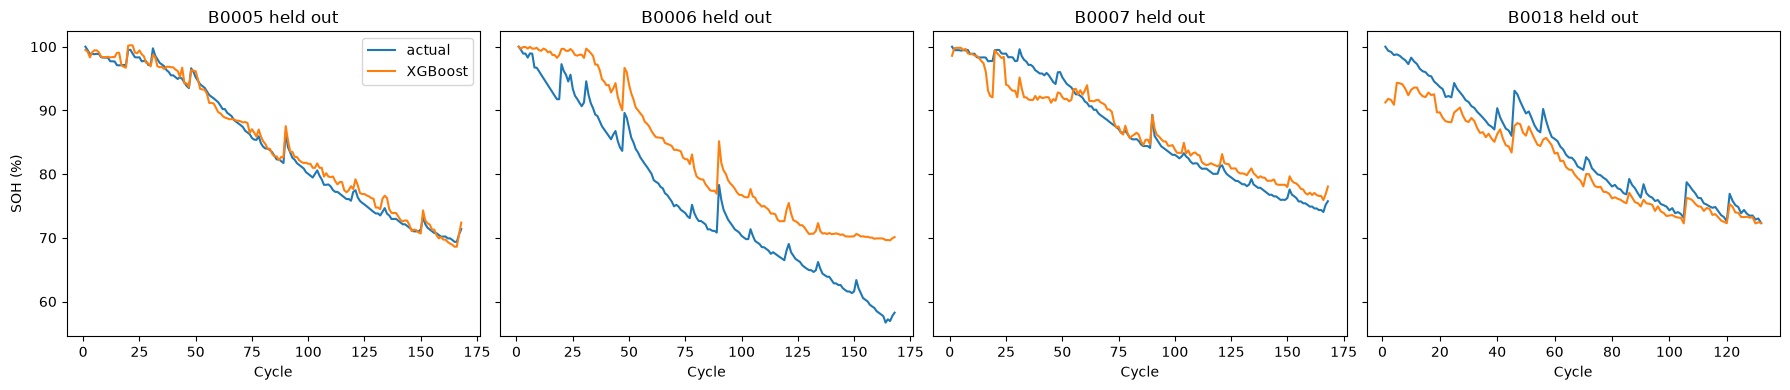

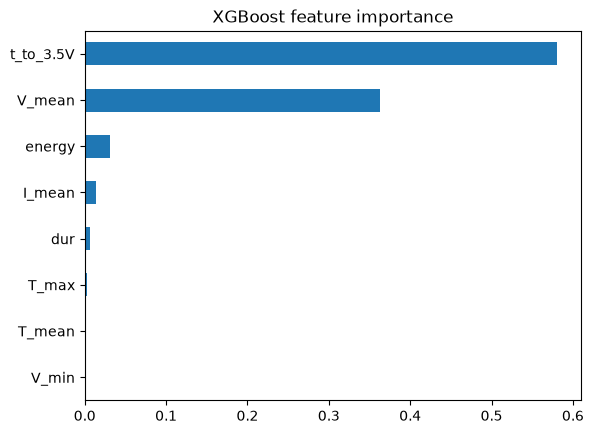

In [8]:
# Lowest SOH reached by each battery (tests the extrapolation idea)
print(df.groupby('cell').SOH.min().round(1))

# Predicted vs actual SOH, one panel per held-out battery
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, cell in zip(axes, cells):
    tr = (groups != cell).values
    te = ~tr
    m = XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05)
    m.fit(X[tr], y[tr])
    p = m.predict(X[te])
    ax.plot(df.loc[te, 'cycle'], y[te], label='actual')
    ax.plot(df.loc[te, 'cycle'], p, label='XGBoost')
    ax.set_title(f'{cell} held out')
    ax.set_xlabel('Cycle')
axes[0].set_ylabel('SOH (%)')
axes[0].legend()
plt.tight_layout()
plt.show()

# Which features matter most
m_all = XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05).fit(X, y)
pd.Series(m_all.feature_importances_, index=X.columns).sort_values().plot.barh(
    title='XGBoost feature importance')
plt.show()

In [9]:
subset = ['t_to_3.5V', 'energy', 'V_mean']

tests = {
    'ridge (3 features)':   (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), subset),
    'xgboost (3 features)': (XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05), subset),
    'ridge (all features)': (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), feat),
    'xgboost (all)':        (XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05), feat),
}

out = []
for name, (m, cols) in tests.items():
    for tr, te in LeaveOneGroupOut().split(X, y, groups):
        m.fit(X.iloc[tr][cols], y.iloc[tr])
        p = m.predict(X.iloc[te][cols])
        out.append(dict(model=name, held_out=groups.iloc[te[0]], **report(y.iloc[te], p)))

r2 = pd.DataFrame(out)
print(r2.groupby('model')[['RMSE', 'MAE', 'R2']].mean().round(3))
print()
print(r2.pivot(index='model', columns='held_out', values='RMSE').round(2))

                       RMSE    MAE     R2
model                                    
ridge (3 features)    2.762  2.582  0.912
ridge (all features)  3.965  3.845  0.817
xgboost (3 features)  3.362  3.086  0.879
xgboost (all)         3.349  2.981  0.864

held_out              B0005  B0006  B0007  B0018
model                                           
ridge (3 features)     1.21   5.44   1.82   2.58
ridge (all features)   1.73   6.07   4.26   3.79
xgboost (3 features)   2.11   6.14   2.43   2.77
xgboost (all)          1.02   7.21   2.32   2.84


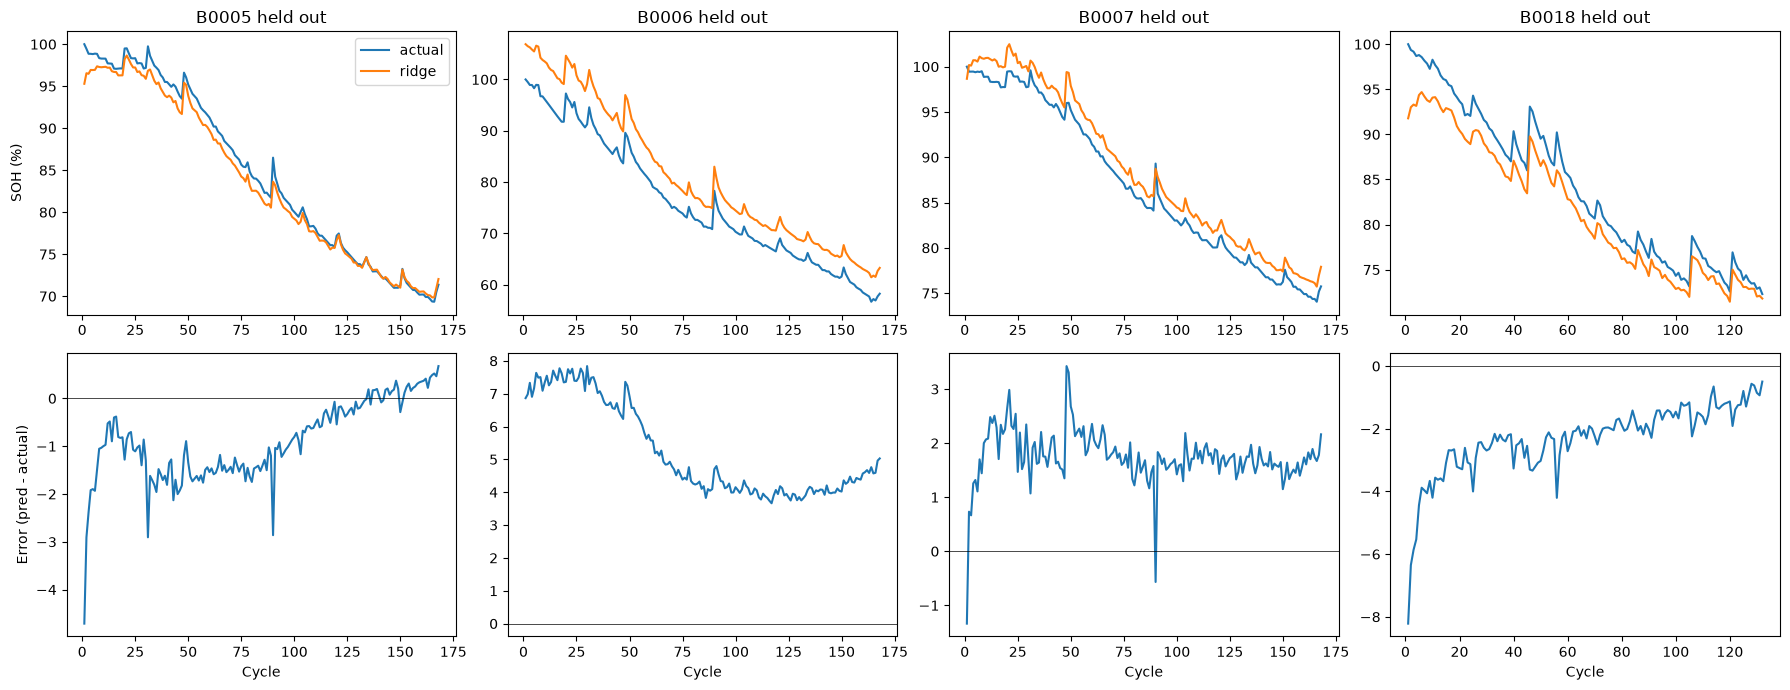

{'t_to_3.5V': np.float64(10.89), 'energy': np.float64(0.05), 'V_mean': np.float64(-0.15)}


In [10]:
final_cols = ['t_to_3.5V', 'energy', 'V_mean']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for j, cell in enumerate(cells):
    tr = (groups != cell).values
    te = ~tr
    m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X[tr][final_cols], y[tr])
    p = m.predict(X[te][final_cols])
    cyc = df.loc[te, 'cycle']
    axes[0, j].plot(cyc, y[te], label='actual')
    axes[0, j].plot(cyc, p, label='ridge')
    axes[0, j].set_title(f'{cell} held out')
    axes[1, j].plot(cyc, p - y[te])
    axes[1, j].axhline(0, color='k', lw=0.5)
    axes[1, j].set_xlabel('Cycle')
axes[0, 0].set_ylabel('SOH (%)'); axes[1, 0].set_ylabel('Error (pred - actual)')
axes[0, 0].legend()
plt.tight_layout(); plt.show()

m_all = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X[final_cols], y)
print(dict(zip(final_cols, m_all[-1].coef_.round(2))))

In [11]:
one = ['t_to_3.5V']
three = ['t_to_3.5V', 'energy', 'V_mean']

tests = {
    'linear (1 feature)': (LinearRegression(), one),
    'ridge (3 features)': (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), three),
}

out = []
for name, (m, cols) in tests.items():
    for tr, te in LeaveOneGroupOut().split(X, y, groups):
        m.fit(X.iloc[tr][cols], y.iloc[tr])
        p = m.predict(X.iloc[te][cols])
        out.append(dict(model=name, held_out=groups.iloc[te[0]], **report(y.iloc[te], p)))

r3 = pd.DataFrame(out)
print(r3.groupby('model')[['RMSE', 'MAE', 'R2']].mean().round(3))
print()
print(r3.pivot(index='model', columns='held_out', values='RMSE').round(2))

                     RMSE    MAE     R2
model                                  
linear (1 feature)  1.827  1.568  0.958
ridge (3 features)  2.762  2.582  0.912

held_out            B0005  B0006  B0007  B0018
model                                         
linear (1 feature)   1.13   2.12   1.49   2.58
ridge (3 features)   1.21   5.44   1.82   2.58


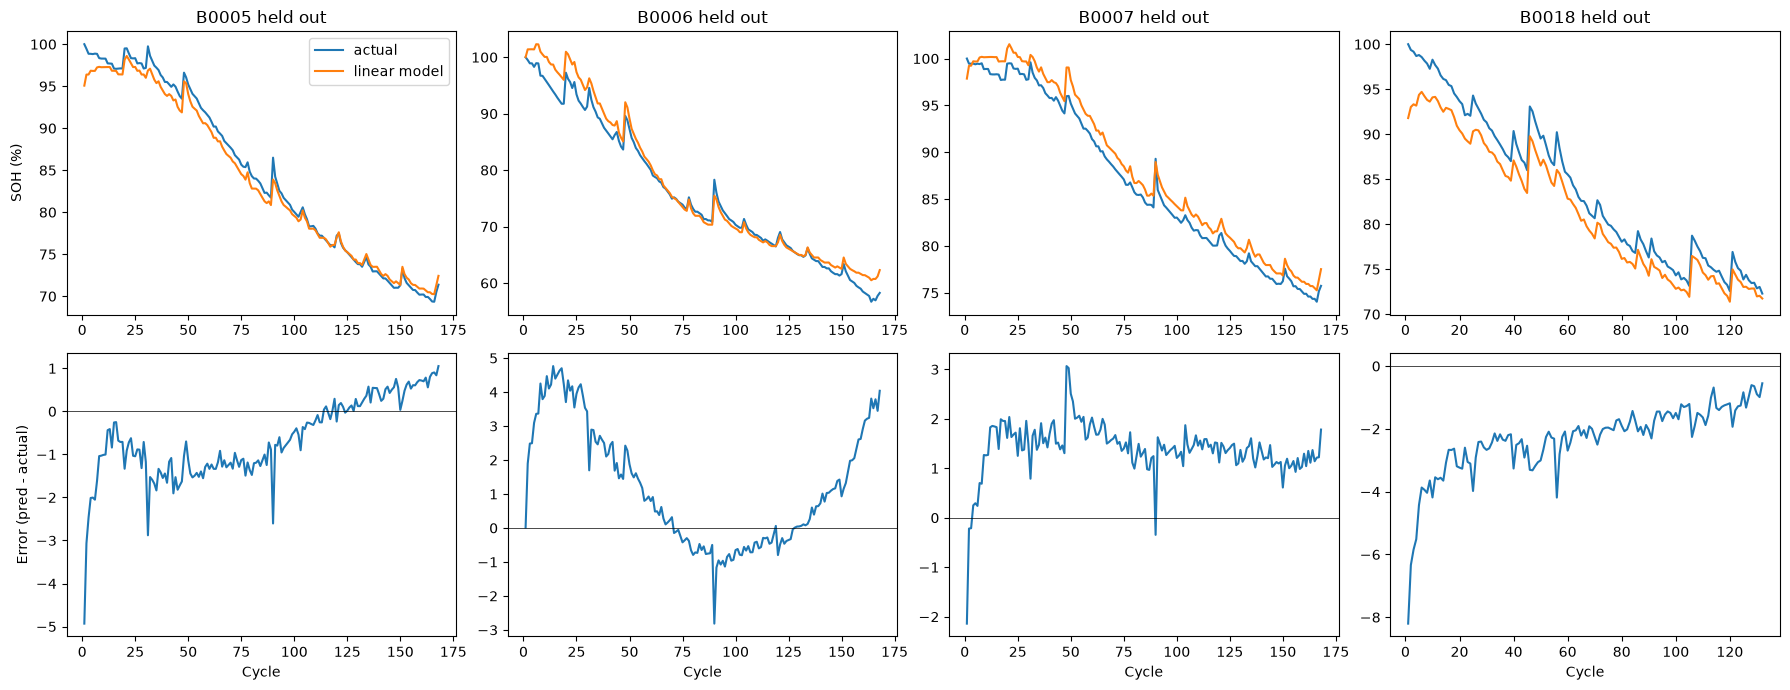

SOH = 0.0235 * t_to_3.5V + 47.07
           RMSE    MAE     R2
held_out                     
B0005     1.125  0.914  0.988
B0006     2.117  1.605  0.971
B0007     1.490  1.428  0.969
B0018     2.578  2.325  0.904
mean      1.828  1.568  0.958


In [12]:
final_cols = ['t_to_3.5V']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for j, cell in enumerate(cells):
    tr = (groups != cell).values
    te = ~tr
    m = LinearRegression().fit(X[tr][final_cols], y[tr])
    p = m.predict(X[te][final_cols])
    cyc = df.loc[te, 'cycle']
    axes[0, j].plot(cyc, y[te], label='actual')
    axes[0, j].plot(cyc, p, label='linear model')
    axes[0, j].set_title(f'{cell} held out')
    axes[1, j].plot(cyc, p - y[te])
    axes[1, j].axhline(0, color='k', lw=0.5)
    axes[1, j].set_xlabel('Cycle')
axes[0, 0].set_ylabel('SOH (%)'); axes[1, 0].set_ylabel('Error (pred - actual)')
axes[0, 0].legend()
plt.tight_layout(); plt.show()

m_all = LinearRegression().fit(X[final_cols], y)
print('SOH = %.4f * t_to_3.5V + %.2f' % (m_all.coef_[0], m_all.intercept_))

summary = (r3[r3.model == 'linear (1 feature)']
           .set_index('held_out')[['RMSE', 'MAE', 'R2']].round(3))
summary.loc['mean'] = summary.mean().round(3)
print(summary)
summary.to_csv('../results_linear_1feature.csv')

In [13]:
# Normalise t_to_3.5V by each cell's first-cycle value
X2 = X.copy()
X2['t_norm'] = X['t_to_3.5V'] / X.groupby(df['cell'])['t_to_3.5V'].transform('first')

out = []
for tr, te in LeaveOneGroupOut().split(X2, y, groups):
    m = LinearRegression().fit(X2.iloc[tr][['t_norm']], y.iloc[tr])
    p = m.predict(X2.iloc[te][['t_norm']])
    out.append(dict(held_out=groups.iloc[te[0]], **report(y.iloc[te], p)))

r4 = pd.DataFrame(out).set_index('held_out').round(3)
r4.loc['mean'] = r4.mean().round(3)
print(r4)

           RMSE    MAE     R2
held_out                     
B0005     0.820  0.658  0.994
B0006     2.201  1.904  0.968
B0007     0.608  0.383  0.995
B0018     1.507  1.446  0.967
mean      1.284  1.098  0.981


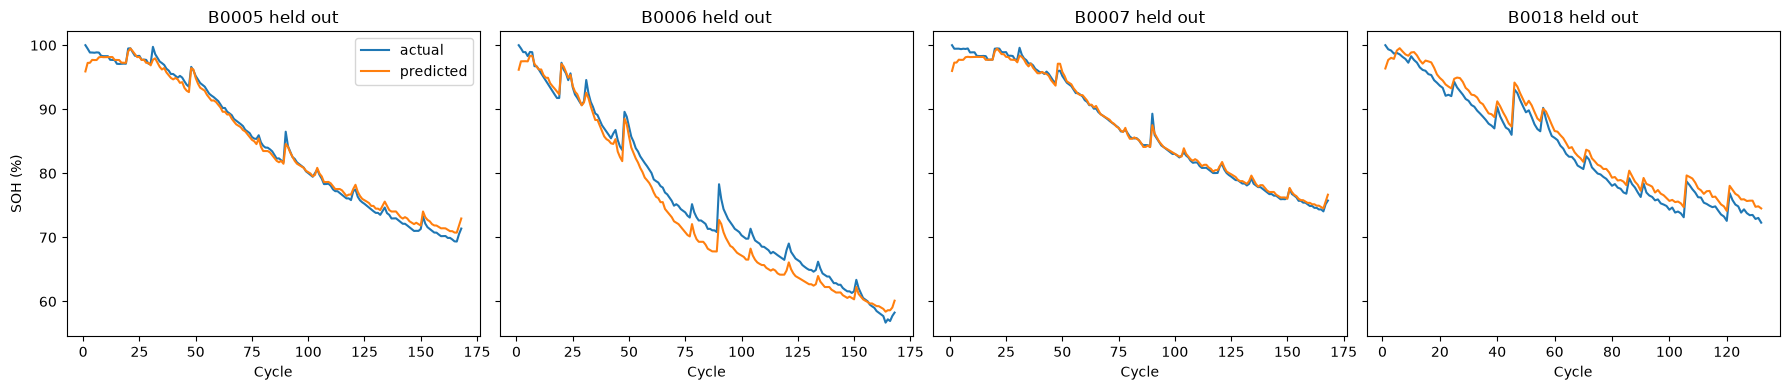

SOH = 48.82 * t_norm + 47.24


In [14]:
final = ['t_norm']
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, cell in zip(axes, cells):
    tr = (groups != cell).values
    te = ~tr
    m = LinearRegression().fit(X2[tr][final], y[tr])
    p = m.predict(X2[te][final])
    ax.plot(df.loc[te, 'cycle'], y[te], label='actual')
    ax.plot(df.loc[te, 'cycle'], p, label='predicted')
    ax.set_title(f'{cell} held out'); ax.set_xlabel('Cycle')
axes[0].set_ylabel('SOH (%)'); axes[0].legend()
plt.tight_layout()
plt.savefig('../final_model.png', dpi=200)
plt.show()

m_final = LinearRegression().fit(X2[final], y)
print('SOH = %.2f * t_norm + %.2f' % (m_final.coef_[0], m_final.intercept_))
r4.to_csv('../results_final_model.csv')